In [22]:
##importing packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.stats import ttest_ind
import statsmodels.formula.api as smf
from statsmodels.gam.api import GLMGam, BSplines
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from scipy.stats import chi2



In [ ]:
#new data babyyyyy

#lets get this new dataset going

#new data babyyyyy
#this is a wierd new format so we are gonna have to break out some new commands
df = pd.read_csv(
    "/Users/dustinh/Downloads/fromelungcancer.txt",
    sep=r"\s+",
    skiprows=11,
    names=["smokedur", "cigpday", "cases", "manyears"],
    engine="python",
)
df


df


df

,smokedur,cigpday,cases,manyears
0,17.5,0.0,1,10366
1,17.5,5.2,0,3121
2,17.5,11.2,0,3577
3,17.5,15.9,0,4317
4,17.5,20.4,0,5683
...,...,...,...,...
58,57.5,11.2,3,449
59,57.5,15.9,5,280
60,57.5,20.4,7,416
61,57.5,27.4,3,284


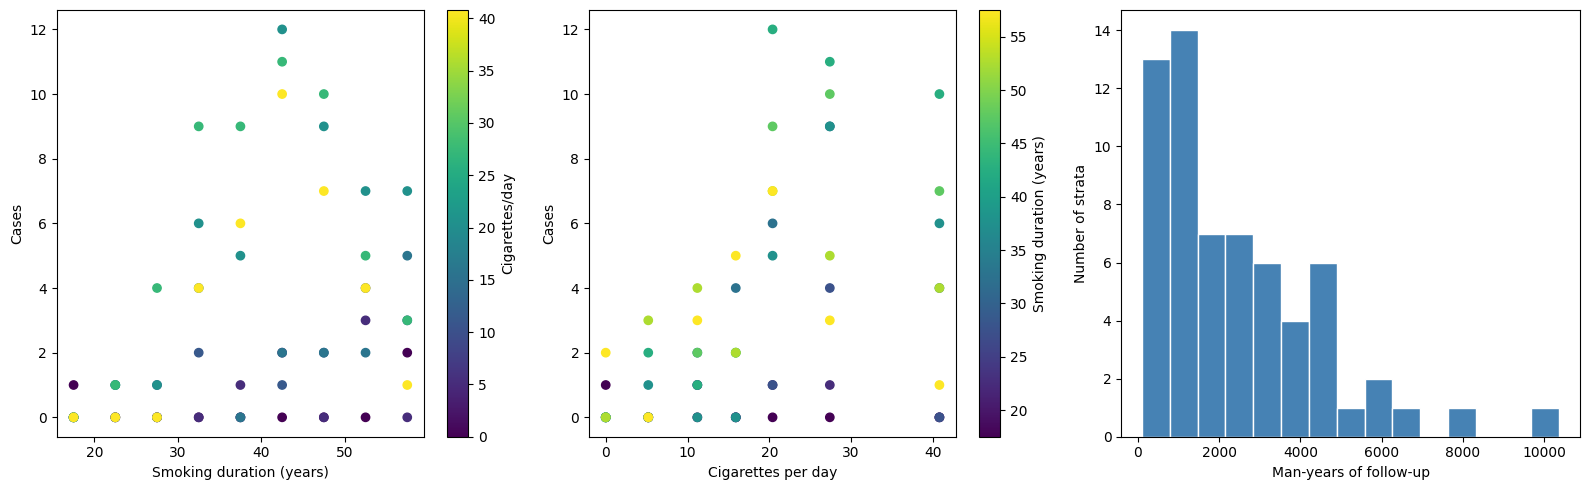

In [12]:
#lets visualize it

#quick exploratory plots to get a feel for the data before modeling

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

#cases vs smoking duration, colored by cigarettes/day
sc1 = axes[0].scatter(df["smokedur"], df["cases"], c=df["cigpday"], cmap="viridis")
axes[0].set_xlabel("Smoking duration (years)")
axes[0].set_ylabel("Cases")
plt.colorbar(sc1, ax=axes[0], label="Cigarettes/day")

#cases vs cigarettes/day, colored by smoking duration
sc2 = axes[1].scatter(df["cigpday"], df["cases"], c=df["smokedur"], cmap="viridis")
axes[1].set_xlabel("Cigarettes per day")
axes[1].set_ylabel("Cases")
plt.colorbar(sc2, ax=axes[1], label="Smoking duration (years)")

#distribution of follow-up time across strata
axes[2].hist(df["manyears"], bins=15, color="steelblue", edgecolor="white")
axes[2].set_xlabel("Man-years of follow-up")
axes[2].set_ylabel("Number of strata")

plt.tight_layout()
plt.show()


In [13]:
#firs we need to to do a basic poisson regression with cigsperday regressed on cases

pois1 = smf.glm(
    "cases ~ cigpday",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["manyears"]),
).fit()
print(pois1.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                  cases   No. Observations:                   63
Model:                            GLM   Df Residuals:                       61
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -222.28
Date:                Wed, 28 Oct 2026   Deviance:                       324.71
Time:                        12:49:47   Pearson chi2:                     526.
No. Iterations:                     6   Pseudo R-squ. (CS):             0.8521
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -8.1593      0.175    -46.607      0.0

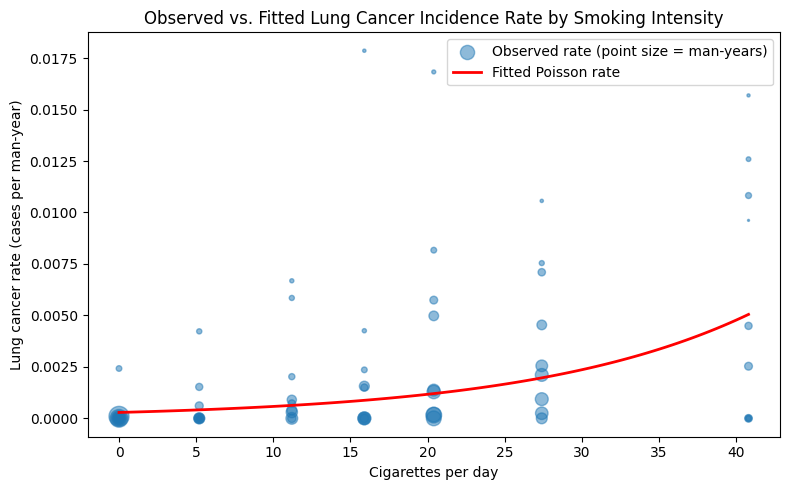

In [15]:
#I wwan to get a visual on this initial regression


#visualizing the Poisson model: observed rates vs. the fitted rate curve

df["rate"] = df["cases"] / df["manyears"]

cig_grid = pd.DataFrame({"cigpday": np.linspace(df["cigpday"].min(), df["cigpday"].max(), 100)})
fitted_rate = np.exp(pois1.params["Intercept"] + pois1.params["cigpday"] * cig_grid["cigpday"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["cigpday"], df["rate"], s=df["manyears"] / 50, alpha=0.5,
           label="Observed rate (point size = man-years)")
ax.plot(cig_grid["cigpday"], fitted_rate, color="red", lw=2, label="Fitted Poisson rate")
ax.set_xlabel("Cigarettes per day")
ax.set_ylabel("Lung cancer rate (cases per man-year)")
ax.set_title("Observed vs. Fitted Lung Cancer Incidence Rate by Smoking Intensity")
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
#next step cases regressed on cigpday and smokedur, with offset for exposure time in manyears

pois2 = smf.glm(
    "cases ~ cigpday + smokedur",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["manyears"]),
).fit()
print(pois2.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                  cases   No. Observations:                   63
Model:                            GLM   Df Residuals:                       60
Model Family:                 Poisson   Df Model:                            2
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -101.04
Date:                Wed, 28 Oct 2026   Deviance:                       82.243
Time:                        13:06:59   Pearson chi2:                     64.3
No. Iterations:                     5   Pseudo R-squ. (CS):             0.9968
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -12.2156      0.378    -32.329      0.0

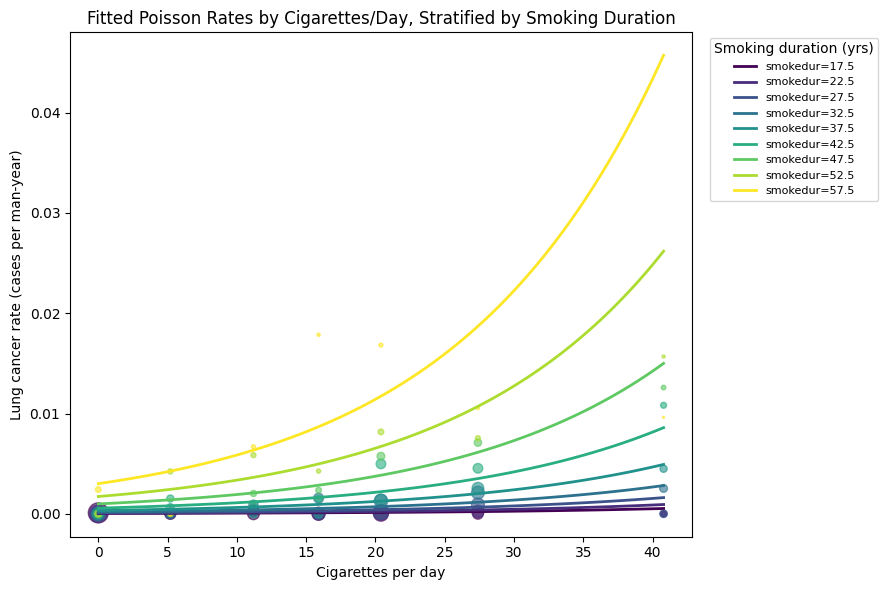

In [17]:
#leets try to take a peek

#visualizing the two-predictor Poisson model: fitted rate curves by cigpday, one per smokedur level

df["rate"] = df["cases"] / df["manyears"]

smokedur_levels = sorted(df["smokedur"].unique())
colors = plt.cm.viridis(np.linspace(0, 1, len(smokedur_levels)))

fig, ax = plt.subplots(figsize=(9, 6))
cig_grid = np.linspace(df["cigpday"].min(), df["cigpday"].max(), 100)

for sd, color in zip(smokedur_levels, colors):
    sub = df[df["smokedur"] == sd]
    ax.scatter(sub["cigpday"], sub["rate"], color=color, s=sub["manyears"] / 50, alpha=0.6)
    fitted = np.exp(pois2.params["Intercept"] + pois2.params["cigpday"] * cig_grid + pois2.params["smokedur"] * sd)
    ax.plot(cig_grid, fitted, color=color, lw=2, label=f"smokedur={sd}")

ax.set_xlabel("Cigarettes per day")
ax.set_ylabel("Lung cancer rate (cases per man-year)")
ax.set_title("Fitted Poisson Rates by Cigarettes/Day, Stratified by Smoking Duration")
ax.legend(title="Smoking duration (yrs)", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


In [ ]:
#now we are running effect modification between cigday and smoker


pois_int = smf.glm(
    "cases ~ cigpday * smokedur",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["manyears"])
).fit()

print(pois_int.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                  cases   No. Observations:                   63
Model:                            GLM   Df Residuals:                       59
Model Family:                 Poisson   Df Model:                            3
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -100.96
Date:                Wed, 28 Oct 2026   Deviance:                       82.076
Time:                        16:45:09   Pearson chi2:                     64.6
No. Iterations:                     5   Pseudo R-squ. (CS):             0.9969
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          -12.4721      0.739  

In [20]:
#now we are adding a qudartic covariate to our model

#first we smake or cigpday squared and our smokedur squared

df["cigpday_sq"] = df["cigpday"] ** 2
df["smokedur_sq"] = df["smokedur"] ** 2

#now lets fit our model

pois_quad = smf.glm(
    "cases ~ cigpday + cigpday_sq + smokedur + smokedur_sq",
    data=df,
    family=sm.families.Poisson(),
    offset=np.log(df["manyears"])
).fit()

print(pois_quad.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                  cases   No. Observations:                   63
Model:                            GLM   Df Residuals:                       58
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -90.605
Date:                Wed, 28 Oct 2026   Deviance:                       61.369
Time:                        21:50:09   Pearson chi2:                     62.1
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9977
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     -16.0728      1.358    -11.836      

In [23]:
#since our models are nested we need to run a likelihood ratio test


lr_stat = -2 * (pois2.llf - pois_quad.llf)
df_diff = pois_quad.df_model - pois2.df_model
p_val = chi2.sf(lr_stat, df_diff)

print("LR statistic:", lr_stat)
print("df difference:", df_diff)
print("p-value:", p_val)

LR statistic: 20.87449041905515
df difference: 2
p-value: 2.9319867222283716e-05
